<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>


# 2.6 — Regressão linear: California Housing Dataset(treino × validação)

Este notebook foi adaptado para aplicar uma Regressão Linear no dataset **California Housing** do scikit-learn. Estimaremos o valor médio de residências na Califórnia com base em 8 atributos demográficos e geográficos.

# 1. Carregamento e Breve Análise dos Dados

Vamos importar o dataset diretamente do scikit-learn, analisar o significado das variáveis e visualizar a relação de algumas características com o preço das casas.

In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Carrega os dados
raw_data = fetch_california_housing(as_frame=True)
df = raw_data.frame

# O preço original está expresso em centenas de milhares de dólares ($100k)
# Vamos multiplicar por 100.000 para facilitar a análise em dólares reais
df['MedHouseVal'] = df['MedHouseVal'] * 100000

print("Descrição das Variáveis:")
# Imprime as seções explicativas das variáveis presentes no DESCR
print("\n".join(raw_data.DESCR.split('\n\n')[1:3]))

display(df.describe())

Descrição das Variáveis:
California Housing dataset
--------------------------
**Data Set Characteristics:**


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,206855.816909
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,115395.615874
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,14999.000000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,119600.000000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,179700.000000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,264725.000000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,500001.000000


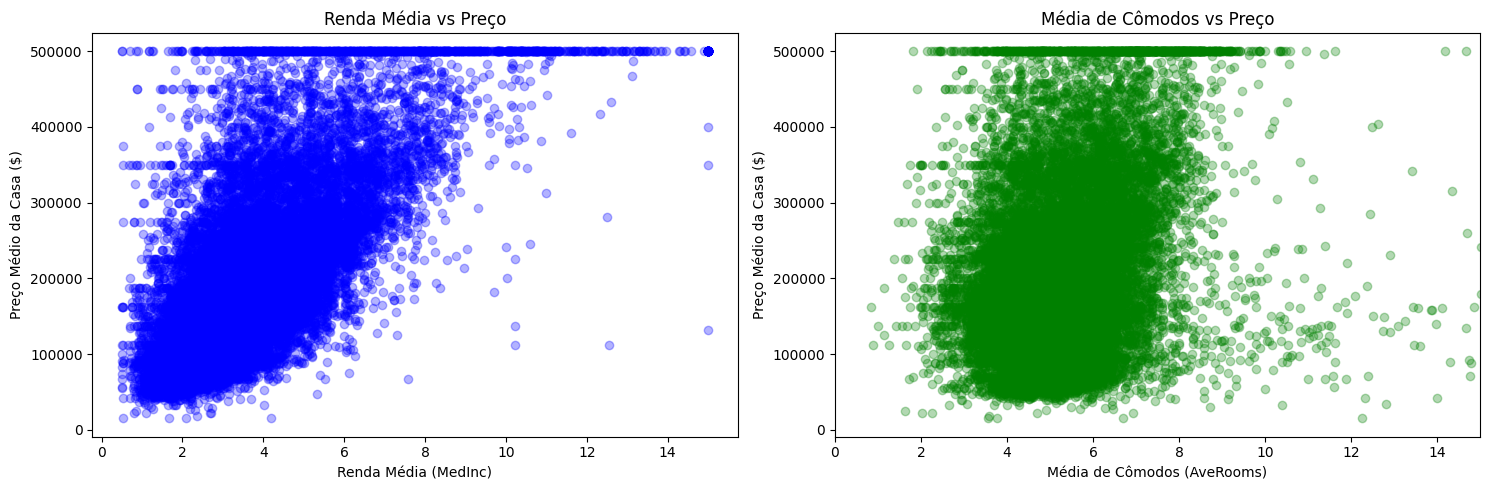

In [2]:
# Gráficos de dispersão contra o Preço
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.3, color='blue')
ax1.set_xlabel('Renda Média (MedInc)')
ax1.set_ylabel('Preço Médio da Casa ($)')
ax1.set_title('Renda Média vs Preço')

ax2.scatter(df['AveRooms'], df['MedHouseVal'], alpha=0.3, color='green')
ax2.set_xlabel('Média de Cômodos (AveRooms)')
ax2.set_ylabel('Preço Médio da Casa ($)')
ax2.set_title('Média de Cômodos vs Preço')
ax2.set_xlim(0, 15) # Limita outlier para melhor visualização

plt.tight_layout()
plt.show()

## 2. Divisão em Treino, Validação e Teste

Dividiremos os dados na proporção 70% treino, 15% validação e 15% teste.

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['MedHouseVal']).to_numpy()
y = df[['MedHouseVal']].to_numpy()

# Primeira divisão: 70% treino e 30% temporário
X_train_raw, X_temp, y_train_raw, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Segunda divisão: divide o temporário pela metade para obter 15% val e 15% teste
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Treino: {X_train_raw.shape[0]} amostras")
print(f"Validação: {X_val_raw.shape[0]} amostras")
print(f"Teste: {X_test_raw.shape[0]} amostras")

Treino: 14448 amostras
Validação: 3096 amostras
Teste: 3096 amostras


## 3. Padronização das Entradas e Saída

Ajustamos o `StandardScaler` apenas nos dados de treino para evitar vazamento de dados.


In [4]:
from sklearn.preprocessing import StandardScaler
import torch

x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

X_train = torch.from_numpy(x_scaler.transform(X_train_raw)).float()
y_train = torch.from_numpy(y_scaler.transform(y_train_raw)).float()

X_val = torch.from_numpy(x_scaler.transform(X_val_raw)).float()
y_val = torch.from_numpy(y_scaler.transform(y_val_raw)).float()

X_test = torch.from_numpy(x_scaler.transform(X_test_raw)).float()
y_test = torch.from_numpy(y_scaler.transform(y_test_raw)).float()

## 4. Treinamento da Rede

Implementamos o modelo linear com 8 entradas e 1 saída, o otimizador SGD com uma taxa de aprendizado adequada e acompanhamos as perdas.


In [5]:
from torch import nn, optim

torch.manual_seed(42)

# Modelo: 8 atributos de entrada, 1 saída linear
model = nn.Linear(8, 1)
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

def train_epoch(model, optimizer, criterion, X, y):
    model.train()
    optimizer.zero_grad()
    y_pred = model(X)
    loss = criterion(y_pred, y)
    loss.backward()
    optimizer.step()
    return loss.item()

def validate_epoch(model, criterion, X, y):
    model.eval()
    with torch.no_grad():
        y_pred = model(X)
        loss = criterion(y_pred, y)
    return loss.item()

n_epochs = 300
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    t_loss = train_epoch(model, optimizer, criterion, X_train, y_train)
    v_loss = validate_epoch(model, criterion, X_val, y_val)

    train_losses.append(t_loss)
    val_losses.append(v_loss)

    if (epoch + 1) % 50 == 0:
        print(f"Época {epoch+1}/{n_epochs} | Custo Treino: {t_loss:.4f} | Custo Validação: {v_loss:.4f}")

Época 50/300 | Custo Treino: 0.5206 | Custo Validação: 0.5195
Época 100/300 | Custo Treino: 0.4595 | Custo Validação: 0.4688
Época 150/300 | Custo Treino: 0.4452 | Custo Validação: 0.4565
Época 200/300 | Custo Treino: 0.4373 | Custo Validação: 0.4493
Época 250/300 | Custo Treino: 0.4311 | Custo Validação: 0.4434
Época 300/300 | Custo Treino: 0.4257 | Custo Validação: 0.4383


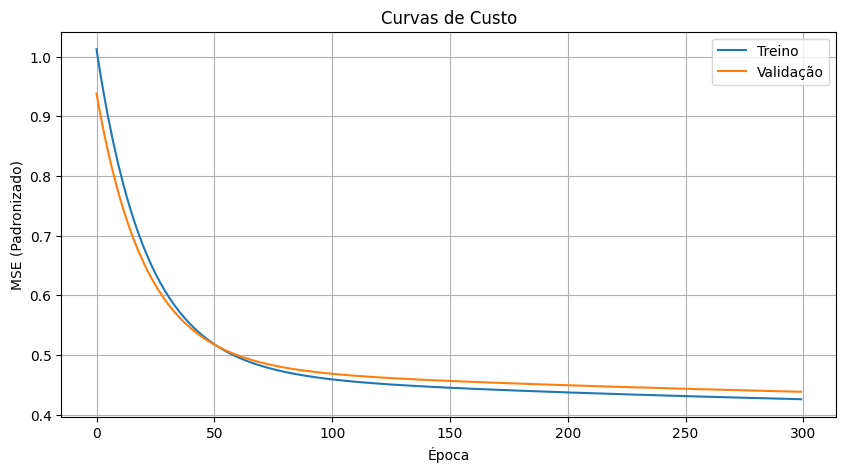

In [6]:
# Plotagem das Curvas de Custo
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Treino')
plt.plot(val_losses, label='Validação')
plt.xlabel('Época')
plt.ylabel('MSE (Padronizado)')
plt.title('Curvas de Custo')
plt.legend()
plt.grid(True)
plt.show()

## 5. Avaliação do RMSE no Teste em Dólares

Calculamos o erro prático em dólares reais e comparamos com um modelo baseline estúpido (que sempre chuta a média histórica).


In [7]:
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test)

# Desfazendo a padronização para medir erro em dólares reais
y_pred_usd = y_scaler.inverse_transform(y_pred_scaled.numpy())

# RMSE do Modelo
rmse_test = np.sqrt(np.mean((y_pred_usd - y_test_raw) ** 2))

# Baseline (Sempre prevê a média de y_train_raw)
y_baseline = np.full_like(y_test_raw, fill_value=y_train_raw.mean())
rmse_baseline = np.sqrt(np.mean((y_baseline - y_test_raw) ** 2))

print(f"RMSE do Modelo no Teste: ${rmse_test:,.2f}")
print(f"RMSE do Baseline no Teste: ${rmse_baseline:,.2f}")

RMSE do Modelo no Teste: $73,882.91
RMSE do Baseline no Teste: $114,992.22


## 6. Análise dos Pesos Aprendidos

Investigamos a contribuição de cada variável.


In [8]:
features = raw_data.feature_names
weights = model.weight.squeeze().detach().numpy()

for name, weight in zip(features, weights):
    print(f"{name:12s}: {weight:+.4f}")

MedInc      : +0.7613
HouseAge    : +0.1689
AveRooms    : -0.2022
AveBedrms   : +0.2022
Population  : +0.0208
AveOccup    : -0.0423
Latitude    : -0.2656
Longitude   : -0.2417


**Análise:**
- As variáveis com maior peso positivo (ex: `MedInc`) são as que mais aumentam o preço previsto.
- As variáveis com peso negativo forte (ex: `Latitude`, `Longitude`) diminuem o preço previsto dependendo do valor.
- Para fazer a comparação dos pesos foi necessario fazer a normalização dos dados.
Se não tivéssemos normalizado os dados, uma variável com escala nativa muito grande (ex: `Population`, na casa de milhares) teria um peso artificialmente minúsculo para compensar sua magnitude, enquanto variáveis pequenas (ex: `AveRooms`) teriam pesos desproporcionalmente gigantes. Com a padronização, todas as variáveis estão na mesma unidade de desvios padrões em relação à média, tornando a comparação direta justa e correta.


## 7. Conclusão

- **O modelo é bom o suficiente?** Embora supere facilmente o baseline estatístico prevendo cerca de 70 mil dolares a menos de erro médio por casa, um erro médio absoluto de 70k em casas de valor médio de 200k ainda é um erro representativo.
- **O que testar para melhorar?** Para capturar relacionamentos não lineares, podemos usar Redes Neurais com camadas ocultas não lineares (com funções de ativação como ReLU) em vez de uma regressão puramente linear, ou experimentar modelos de árvore (como XGBoost/Random Forest).